#  Kedi mi Köpek mi? (Dogs vs. Cats Redux)
Bir fotoğrafta kedi mi köpek mi olduğunu bulmaya çalışıyoruz. Transfer Learning.Sıfırdan bir sinir ağı eğitmek için çok veri ve zaman gerekir. Bunun yerine milyonlarca fotoğrafla (ImageNet) önceden eğitilmiş bir ağı (MobileNetV2) kullanıyoruz. Bu ağ kenar, doku, göz, kulak gibi görsel özellikleri zaten tanıyor. Onun üzerine sadece küçük bir son katman ekleyip "kedi mi köpek mi" kararını vermesini öğretiyoruz.

In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss, accuracy_score

print('TensorFlow sürümü:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow sürümü: 2.21.0
GPU: []


In [2]:
kok = '.'

def klasor_hazirla(ad):
    yol = os.path.join(kok, ad)
    if not os.path.isdir(yol):
        yol = os.path.join(kok, ad + '_acik')
        if not os.path.isdir(yol):
            with zipfile.ZipFile(os.path.join(kok, ad + '.zip')) as z:
                z.extractall(yol)
    ic = os.path.join(yol, ad)                       
    return ic if os.path.isdir(ic) else yol

train_dir = klasor_hazirla('train')
test_dir = klasor_hazirla('test')
sample = pd.read_csv(os.path.join(kok, 'sample_submission.csv'))

In [3]:
test_dosyalar = sorted((f for f in os.listdir(test_dir) if f.lower().endswith('.jpg')),
                       key=lambda f: int(os.path.splitext(f)[0]))
test = pd.DataFrame({'id': [int(os.path.splitext(f)[0]) for f in test_dosyalar],
                     'yol': [os.path.join(test_dir, f) for f in test_dosyalar]})

In [4]:
dosyalar = sorted(f for f in os.listdir(train_dir) if f.lower().endswith('.jpg'))
train = pd.DataFrame({'yol': [os.path.join(train_dir, f) for f in dosyalar],
                      'etiket': [1 if f.startswith('dog') else 0 for f in dosyalar]})

In [5]:
print('eğitim:', len(train), '| test:', len(test), '| sample_submission:', sample.shape)

eğitim: 25000 | test: 12500 | sample_submission: (12500, 2)


In [6]:
sample.head()

,id,label
0,1,0.5
1,2,0.5
2,3,0.5
3,4,0.5
4,5,0.5


In [7]:
print('Sınıf dağılımı (0 = kedi, 1 = köpek):')
print(train.etiket.value_counts())

Sınıf dağılımı (0 = kedi, 1 = köpek):
etiket
0    12500
1    12500
Name: count, dtype: int64


Sınıflar tam dengeli (12.500 kedi, 12.500 köpek), yani sınıf dengesizliği sorunu yok.

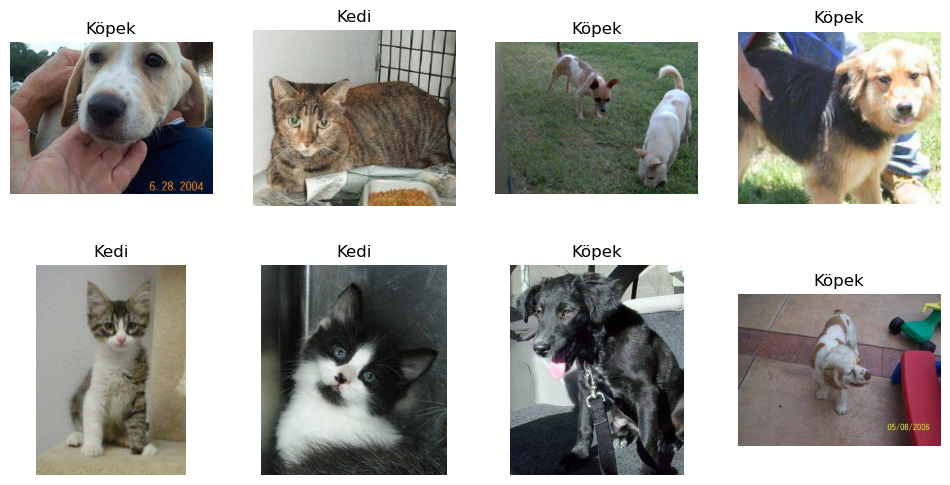

In [8]:
rastgele = train.sample(8, random_state=1)
fig, eksenler = plt.subplots(2, 4, figsize=(12, 6))
for ax, (_, satir) in zip(eksenler.ravel(), rastgele.iterrows()):
    ax.imshow(Image.open(satir.yol))
    ax.set_title('Köpek' if satir.etiket == 1 else 'Kedi')
    ax.axis('off')

In [9]:
boyutlar = pd.DataFrame([Image.open(y).size for y in train.yol.sample(500, random_state=0)], columns=['genişlik', 'yükseklik'])
print(boyutlar.describe().loc[['min', 'mean', 'max']].round(0))

      genişlik  yükseklik
min       50.0       49.0
mean     399.0      358.0
max      500.0      500.0


In [10]:
def bozuk_mu(yol):
    try:
        Image.open(yol).verify()
        return False
    except Exception:
        return True

bozuk = train.yol.apply(bozuk_mu)
print('bozuk fotoğraf sayısı:', bozuk.sum())
train = train[~bozuk].reset_index(drop=True)

bozuk fotoğraf sayısı: 0


In [11]:
ORNEK = None
if ORNEK:
    train = train.groupby('etiket').sample(ORNEK, random_state=0).reset_index(drop=True)
print('eğitimde kullanılacak fotoğraf sayısı:', len(train))

eğitimde kullanılacak fotoğraf sayısı: 25000


In [12]:
BOYUT = 160
BATCH = 64

egitim_df, dogrulama_df = train_test_split(train, test_size=0.2, stratify=train.etiket, random_state=42)
print('eğitim:', len(egitim_df), '| doğrulama:', len(dogrulama_df))

def yukle(yol, etiket):
    resim = tf.io.decode_jpeg(tf.io.read_file(yol), channels=3)
    resim = tf.image.resize(resim, (BOYUT, BOYUT))
    return resim, tf.cast(etiket, tf.float32)

def veri_hatti(yollar, etiketler, karistir=False, hata_atla=False):
    ds = tf.data.Dataset.from_tensor_slices((yollar, etiketler))
    if karistir:
        ds = ds.shuffle(len(yollar), seed=42)
    ds = ds.map(yukle, num_parallel_calls=tf.data.AUTOTUNE)
    if hata_atla:
        ds = ds.ignore_errors() if hasattr(ds, 'ignore_errors') else ds.apply(tf.data.experimental.ignore_errors())
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

egitim_ds = veri_hatti(egitim_df.yol.values, egitim_df.etiket.values, karistir=True, hata_atla=True)
dogrulama_ds = veri_hatti(dogrulama_df.yol.values, dogrulama_df.etiket.values)

eğitim: 20000 | doğrulama: 5000


In [13]:
temel = keras.applications.MobileNetV2(input_shape=(BOYUT, BOYUT, 3), include_top=False, weights='imagenet')
temel.trainable = False     

girdi = keras.Input(shape=(BOYUT, BOYUT, 3))
x = layers.RandomFlip('horizontal')(girdi)
x = layers.RandomRotation(0.1)(x)
x = layers.RandomZoom(0.1)(x)
x = layers.Rescaling(1 / 127.5, offset=-1)(x)       
x = temel(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
cikis = layers.Dense(1, activation='sigmoid')(x)

model = keras.Model(girdi, cikis)
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
print('Eğitilebilir parametre sayısı:', sum(int(np.prod(w.shape)) for w in model.trainable_weights))
print('Toplam parametre sayısı     :', model.count_params())

Eğitilebilir parametre sayısı: 1281
Toplam parametre sayısı     : 2259265


In [14]:
gecmis = model.fit(egitim_ds, validation_data=dogrulama_ds, epochs=3)

Epoch 1/3
    313/Unknown 294s 904ms/step - accuracy: 0.8936 - loss: 0.2432

D:\Anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


313/313 ━━━━━━━━━━━━━━━━━━━━ 354s 1s/step - accuracy: 0.9398 - loss: 0.1481 - val_accuracy: 0.9814 - val_loss: 0.0590
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 328s 1s/step - accuracy: 0.9631 - loss: 0.0945 - val_accuracy: 0.9798 - val_loss: 0.0556
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 323s 1s/step - accuracy: 0.9665 - loss: 0.0861 - val_accuracy: 0.9820 - val_loss: 0.0498


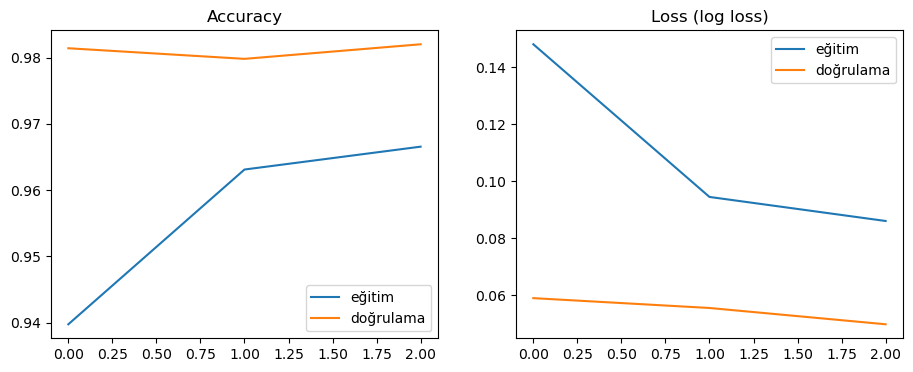

In [15]:
fig, eksenler = plt.subplots(1, 2, figsize=(11, 4))
eksenler[0].plot(gecmis.history['accuracy'], label='eğitim')
eksenler[0].plot(gecmis.history['val_accuracy'], label='doğrulama')
eksenler[0].set_title('Accuracy')
eksenler[0].legend()
eksenler[1].plot(gecmis.history['loss'], label='eğitim')
eksenler[1].plot(gecmis.history['val_loss'], label='doğrulama')
eksenler[1].set_title('Loss (log loss)')
eksenler[1].legend()
plt.show()

In [16]:
dogrulama_olasilik = model.predict(dogrulama_ds).ravel()
y_dogrulama = dogrulama_df.etiket.values

dogrulama_acc = accuracy_score(y_dogrulama, dogrulama_olasilik > 0.5)
dogrulama_logloss = log_loss(y_dogrulama, dogrulama_olasilik)
print(f'Doğrulama accuracy: %{dogrulama_acc * 100:.2f}')
print(f'Doğrulama log loss: {dogrulama_logloss:.4f}')

79/79 ━━━━━━━━━━━━━━━━━━━━ 61s 747ms/step
Doğrulama accuracy: %98.20
Doğrulama log loss: 0.0498


In [17]:
print('Kırpmadan  log loss:', round(log_loss(y_dogrulama, dogrulama_olasilik), 4))
print('Kırparak   log loss:', round(log_loss(y_dogrulama, np.clip(dogrulama_olasilik, 0.01, 0.99)), 4))

Kırpmadan  log loss: 0.0498
Kırparak   log loss: 0.0566


yanlış tahmin sayısı (doğrulamada): 90 / 5000


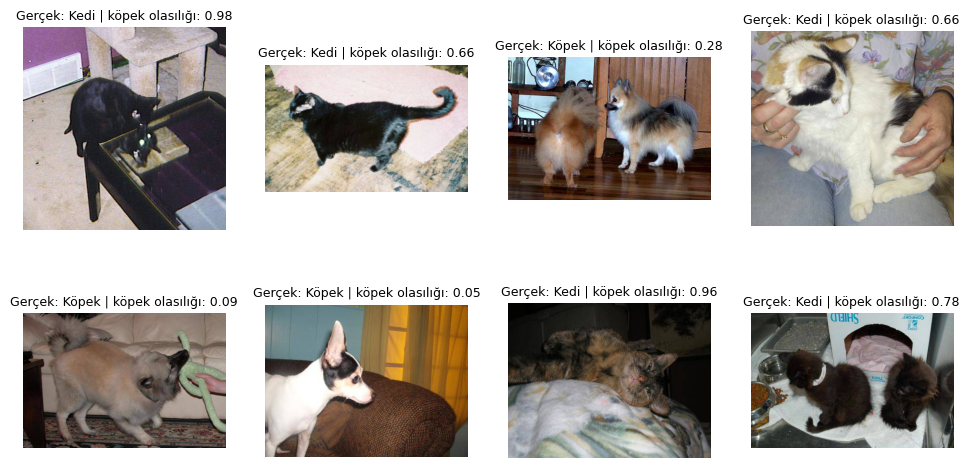

In [18]:
yanlis = np.where((dogrulama_olasilik > 0.5) != (y_dogrulama == 1))[0][:8]
print('yanlış tahmin sayısı (doğrulamada):', int(((dogrulama_olasilik > 0.5) != (y_dogrulama == 1)).sum()), '/', len(y_dogrulama))
if len(yanlis) > 0:
    fig, eksenler = plt.subplots(2, 4, figsize=(12, 6))
    for ax, i in zip(eksenler.ravel(), yanlis):
        ax.imshow(Image.open(dogrulama_df.yol.values[i]))
        gercek = 'Köpek' if y_dogrulama[i] == 1 else 'Kedi'
        ax.set_title(f'Gerçek: {gercek} | köpek olasılığı: {dogrulama_olasilik[i]:.2f}', fontsize=9)
        ax.axis('off')
    plt.show()

In [19]:
test_ds = veri_hatti(test.yol.values, np.zeros(len(test)))     
test_olasilik = np.clip(model.predict(test_ds).ravel(), 0.01, 0.99)
assert len(test_olasilik) == len(test), 'tahmin sayısı test sayısıyla uyuşmuyor'

sonuc = pd.DataFrame({'id': test.id, 'label': test_olasilik})
sonuc = sample[['id']].merge(sonuc, on='id', how='left')      
sonuc.to_csv('sonuc1.csv', index=False)

196/196 ━━━━━━━━━━━━━━━━━━━━ 145s 739ms/step


In [20]:
sonuc.shape

(12500, 2)

In [21]:
sonuc.head()

,id,label
0,1,0.99
1,2,0.99
2,3,0.99
3,4,0.99
4,5,0.01


In [22]:
print('sütunlar sample ile aynı mı:', list(sonuc.columns) == list(sample.columns))
print('id\'ler aynı mı           :', (sonuc.id.values == sample.id.values).all())
print('boş değer var mı          :', sonuc.label.isna().any())
print('olasılık aralığı          :', round(sonuc.label.min(), 3), '-', round(sonuc.label.max(), 3))
print('köpek tahmin oranı (>0.5) : %', round((sonuc.label > 0.5).mean() * 100, 1), '(gerçek oran yaklaşık %50 olmalı)')

sütunlar sample ile aynı mı: True
id'ler aynı mı           : True
boş değer var mı          : False
olasılık aralığı          : 0.01 - 0.99
köpek tahmin oranı (>0.5) : % 50.4 (gerçek oran yaklaşık %50 olmalı)


In [23]:
model.save('model.keras')
print('model.keras kaydedildi')

model.keras kaydedildi


- Transfer learning, bu problemde sıfırdan sinir ağı eğitmekten çok daha verimli: önceden eğitilmiş MobileNetV2 görsel özellikleri zaten tanıdığı için sadece küçük bir son katmanı eğitmemiz yetti ve üç turda eğitim bitti.
- Veri artırma (yatay çevirme, döndürme, yakınlaştırma) ve Dropout, modelin 20 bin fotoğrafı ezberlemesini azalttı. Eğitim ve doğrulama eğrilerinin birbirine yakınlığı bunu gösteriyor..
- Yukarıdaki hücrelerde modelin doğrulama accuracy ve log loss değerleri ile yanıldığı fotoğraf örnekleri görülüyor. Test tahminlerinde köpek oranının yaklaşık %50 çıkması da (gerçek dağılım dengeli) modelin test verisinde mantıklı çalıştığını gösteriyor.